In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import numpy as np

df = pd.read_csv('School_Data_CSV.csv', encoding='latin1')

C:\Users\jessi\AppData\Local\Temp\ipykernel_19788\3781501127.py:6: DtypeWarning: Columns (0: emisno, 7: new_long) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('School_Data_CSV.csv', encoding='latin1')


In [2]:

# 2. Basic Dataset Overview
print("--- DATASET SHAPE ---")
print(f"Rows: {df.shape[0]} | Columns: {df.shape[1]}\n")

print("--- DATA TYPES & NON-NULL COUNTS ---")
df.info()

# 3. Assess Missing Values
print("\n--- MISSING VALUES PER COLUMN ---")
missing_data = df.isnull().sum()
missing_percent = (missing_data / len(df)) * 100
missing_df = pd.DataFrame({'Missing Count': missing_data, 'Percentage (%)': missing_percent})
display(missing_df[missing_df['Missing Count'] > 0].sort_values(by='Percentage (%)', ascending=False))

# 4. Check for Duplicates
print(f"\n--- TOTAL DUPLICATE ROWS ---")
print(df.duplicated().sum())

# 5. Inspect a Sample of the Data
display(df.head())

--- DATASET SHAPE ---
Rows: 199853 | Columns: 9

--- DATA TYPES & NON-NULL COUNTS ---
<class 'pandas.DataFrame'>
RangeIndex: 199853 entries, 0 to 199852
Data columns (total 9 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   emisno            199853 non-null  object 
 1   centername        193922 non-null  str    
 2   institution_name  133926 non-null  str    
 3   centreno          199823 non-null  str    
 4   quintile          197040 non-null  str    
 5   ward_id           199071 non-null  str    
 6   street_address    193150 non-null  str    
 7   new_long          167741 non-null  object 
 8   new_lat           84107 non-null   float64
dtypes: float64(1), object(2), str(6)
memory usage: 13.7+ MB

--- MISSING VALUES PER COLUMN ---


,Missing Count,Percentage (%)
new_lat,115746,57.915568
institution_name,65927,32.987746
new_long,32112,16.067810
street_address,6703,3.353965
centername,5931,2.967681
quintile,2813,1.407535
ward_id,782,0.391288
centreno,30,0.015011



--- TOTAL DUPLICATE ROWS ---
766


,emisno,centername,institution_name,centreno,quintile,ward_id,street_address,new_long,new_lat
0,200100005,ABERDEEN SECONDARY SCHOOL (20),ABERDEEN SECONDARY SCHOOL,4201001,3,21001001,"10 PARLIAMENT STREET, ABERDEEN, 6270",24.06183,-32.47385
1,200100012,ADELAIDE GYMNASIUM,ADELAIDE GYMNASIUM,4171044,4,21208001,"WELSH STREET, ADELAIDE, 5760",26.29476,-32.71036
2,200100018,AEROVILLE(SOMERSET EAST) (20),AEROVILLE SECONDARY SCHOOL,4201002,3,21002002,"PERSEVERANCE DR, SOMERSET EAST, 5850",25.60073,-32.74592
3,200100019,Al Azhar Institute,AL-AZHAR PRIMARY SCHOOL,4222001,NOT APPLICABLE,29500009,"42 RUDOLPH STREET, MALABAR, PORT ELIZABETH, 6000",25.53563,-33.91924
4,200100021,ALEXANDER ROAD HIGH SCHOOL,ALEXANDER ROAD HIGH SCHOOL,4221002,5,29300007,"ALEXANDER ROAD, NEWTON PARK, PORT ELIZABETH, 6055",25.57181,-33.94147


In [3]:
import pandas as pd
import numpy as np

# Assuming df is already loaded from Step 1:
# df = pd.read_csv('School_Data_CSV.csv', encoding='latin1', low_memory=False)

print("Starting Row Count:", len(df))

# 1. Remove Exact Duplicate Rows
df.drop_duplicates(inplace=True)
print("Row Count after dropping duplicates:", len(df))

# 2. Clean the 'quintile' column
# We need to standardize values like 'Q1', 'NQ2', 'TO BE UPDATED', '.', etc.
def clean_quintile(val):
    if pd.isna(val):
        return np.nan
    val_str = str(val).upper().strip()
    # Extract numeric part if it exists (handles 'Q1', 'NQ2', etc.)
    import re
    match = re.search(r'[1-5]', val_str)
    if match:
        return int(match.group())
    else:
        # For values like 'TO BE UPDATED', '.', 'NOT APPLICABLE', '99', 'UNKNOWN'
        return np.nan

df['quintile_cleaned'] = df['quintile'].apply(clean_quintile)

# 3. Clean Geographic Coordinates
# 'new_long' has issues like '.' instead of valid numbers
# We force conversion to numeric, turning invalid strings into NaN
df['new_long_cleaned'] = pd.to_numeric(df['new_long'], errors='coerce')

# Ensure 'new_lat' is float
df['new_lat'] = pd.to_numeric(df['new_lat'], errors='coerce')

# 4. Handle Missing Names (Coalescing centername and institution_name)
# If institution_name is missing, we fill it with centername
df['institution_name'] = df['institution_name'].fillna(df['centername'])

# 5. Drop rows where we still don't have a name or EMIS number, as these are unidentifiable
df.dropna(subset=['emisno', 'institution_name'], inplace=True)
print("Row Count after dropping unidentifiable records:", len(df))

# 6. Final check of missing values on the critical columns
print("\n--- CLEANED DATA SUMMARY ---")
print("Remaining Missing Values in Key Columns:")
print(df[['emisno', 'institution_name', 'quintile_cleaned', 'new_long_cleaned', 'new_lat']].isnull().sum())

# Display the cleaned dataframe preview
display(df[['emisno', 'institution_name', 'quintile_cleaned', 'new_long_cleaned', 'new_lat']].head())

Starting Row Count: 199853
Row Count after dropping duplicates: 199087
Row Count after dropping unidentifiable records: 199063

--- CLEANED DATA SUMMARY ---
Remaining Missing Values in Key Columns:
emisno                   0
institution_name         0
quintile_cleaned     41867
new_long_cleaned     39349
new_lat             115425
dtype: int64


,emisno,institution_name,quintile_cleaned,new_long_cleaned,new_lat
0,200100005,ABERDEEN SECONDARY SCHOOL,3.0,24.06183,-32.47385
1,200100012,ADELAIDE GYMNASIUM,4.0,26.29476,-32.71036
2,200100018,AEROVILLE SECONDARY SCHOOL,3.0,25.60073,-32.74592
3,200100019,AL-AZHAR PRIMARY SCHOOL,NaN,25.53563,-33.91924
4,200100021,ALEXANDER ROAD HIGH SCHOOL,5.0,25.57181,-33.94147


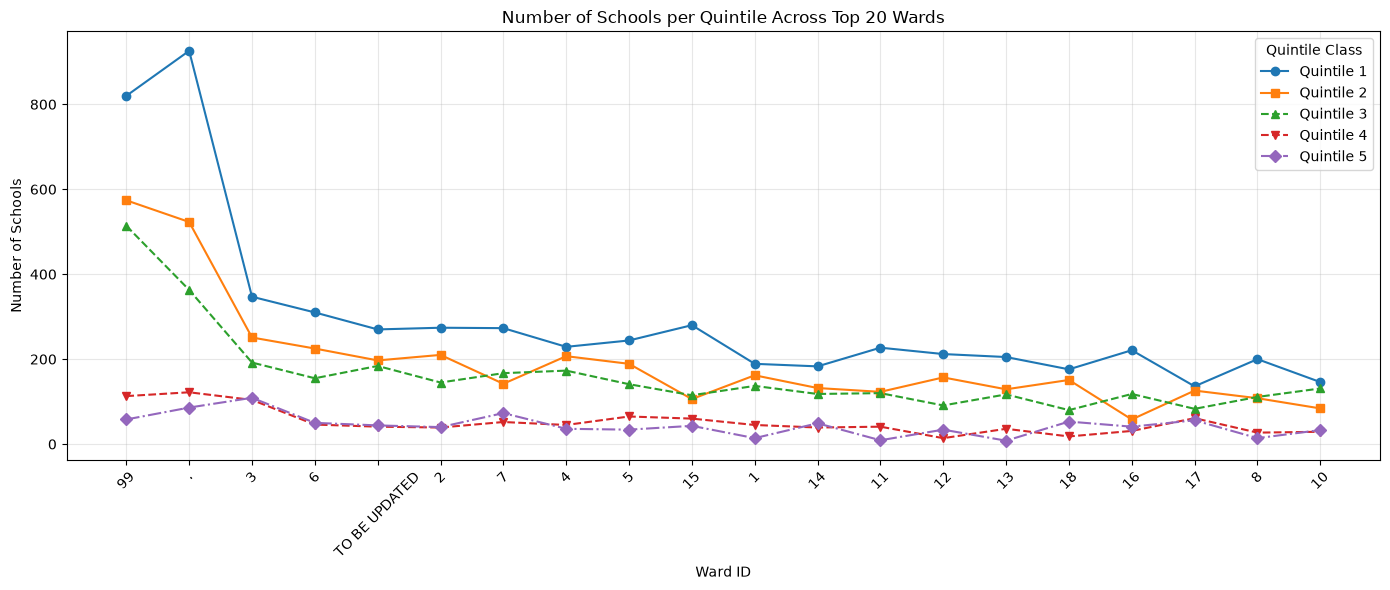

In [4]:
import matplotlib.pyplot as plt

# 1. Prepare the Data
# Group by ward_id and quintile_cleaned, then count the number of schools
# unstack() pivots the quintiles into columns. fill_value=0 handles wards missing certain quintiles.
ward_quintile_counts = df.groupby(['ward_id', 'quintile_cleaned']).size().unstack(fill_value=0)

# Calculate total schools per ward to find the top 20 busiest wards
ward_quintile_counts['total_schools'] = ward_quintile_counts.sum(axis=1)
top_wards = ward_quintile_counts.sort_values(by='total_schools', ascending=False).head(20)

# Drop the 'total_schools' column as we only want to plot the quintiles
top_wards = top_wards.drop(columns=['total_schools'])

# Convert the ward_id index to strings for categorical plotting on the x-axis
x_labels = top_wards.index.astype(str)

# 2. Create the Line Plot
fig, ax1 = plt.subplots(figsize=(14, 6))

# Plot each quintile line (checking if the column exists to avoid KeyError)
if 1 in top_wards.columns:
    ax1.plot(x_labels, top_wards[1], color='#1f77b4', marker='o', linestyle='-', label='Quintile 1')
if 2 in top_wards.columns:
    ax1.plot(x_labels, top_wards[2], color='#ff7f0e', marker='s', linestyle='-', label='Quintile 2')
if 3 in top_wards.columns:
    ax1.plot(x_labels, top_wards[3], color='#2ca02c', marker='^', linestyle='--', label='Quintile 3')
if 4 in top_wards.columns:
    ax1.plot(x_labels, top_wards[4], color='#d62728', marker='v', linestyle='--', label='Quintile 4')
if 5 in top_wards.columns:
    ax1.plot(x_labels, top_wards[5], color='#9467bd', marker='D', linestyle='-.', label='Quintile 5')

# 3. Format the Chart
ax1.set_xlabel('Ward ID')
ax1.set_ylabel('Number of Schools')
ax1.set_title('Number of Schools per Quintile Across Top 20 Wards')
ax1.legend(title='Quintile Class', loc='upper right')
ax1.grid(alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()

# 4. Save and Display
plt.savefig('schools_per_quintile_across_wards.png', dpi=150)
plt.show()

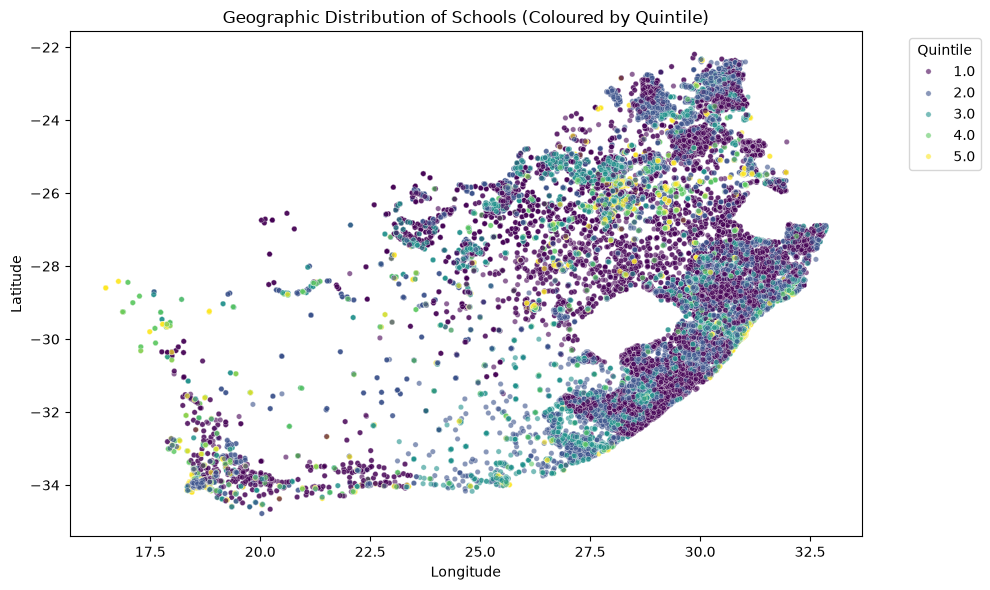

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Prepare Data
# Drop rows where either latitude or longitude is missing to ensure a clean plot
plot_data = df.dropna(subset=['new_long_cleaned', 'new_lat']).copy()

# Filter out extreme outliers (e.g., coordinates typed incorrectly that fall outside South Africa)
# South Africa bounds are roughly Longitude 16 to 33, Latitude -35 to -22
plot_data = plot_data[
    (plot_data['new_long_cleaned'] > 15) & (plot_data['new_long_cleaned'] < 35) &
    (plot_data['new_lat'] > -36) & (plot_data['new_lat'] < -21)
]

# 2. Create Scatter Plot
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=plot_data, 
    x='new_long_cleaned', 
    y='new_lat',
    hue='quintile_cleaned', 
    palette='viridis', 
    alpha=0.6, 
    s=15  # Smaller dot size since there are thousands of schools
)

# 3. Format the Chart
plt.title('Geographic Distribution of Schools (Coloured by Quintile)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.legend(title='Quintile', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.savefig('school_locations_scatter.png', dpi=150)
plt.show()

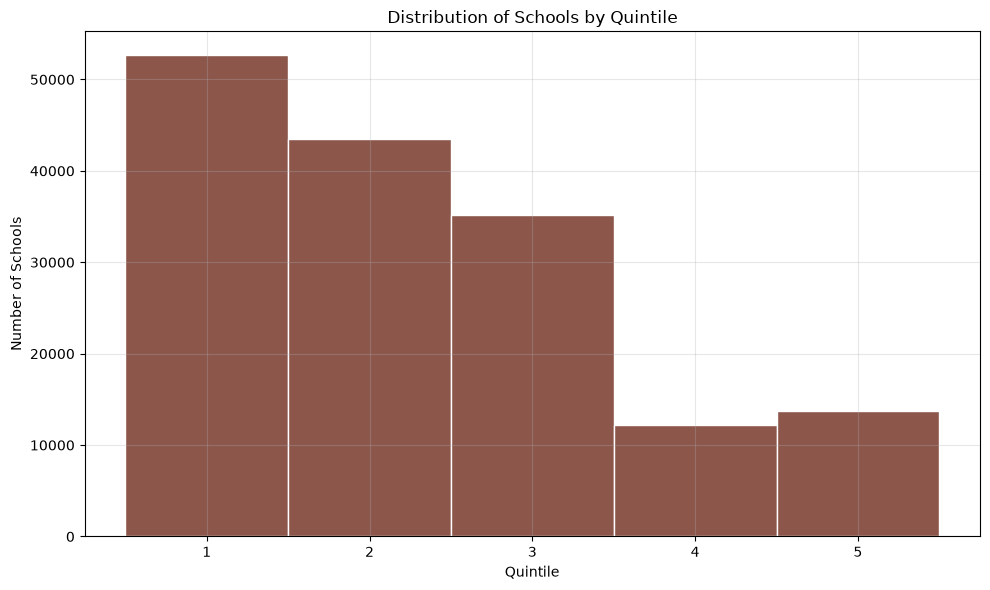

In [6]:
import matplotlib.pyplot as plt

# 1. Prepare Data
# Drop missing values from quintile_cleaned to plot the distribution accurately
hist_data = df['quintile_cleaned'].dropna()

# 2. Create Histogram
plt.figure(figsize=(10, 6))
# Using predefined bin edges centers the bars precisely over 1, 2, 3, 4, and 5
plt.hist(hist_data, bins=[0.5, 1.5, 2.5, 3.5, 4.5, 5.5], color='#8c564b', edgecolor='white')

# 3. Format the Chart
plt.title('Distribution of Schools by Quintile')
plt.xlabel('Quintile')
plt.ylabel('Number of Schools')
plt.xticks([1, 2, 3, 4, 5])  # Force x-axis to only show whole number quintiles
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('schools_quintile_histogram.png', dpi=150)
plt.show()